[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_vcrix_har/BA_L3_vcrix_har.ipynb)

# BA_L3_vcrix_har: A HAR Forecast of Next Month's CRIX Volatility

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

HAR model for the realised volatility of CRIX over the next 30 days, estimated on 2018-2023 and tested on 2024 to February 2026 against the naive forecast.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'legend.fontsize': 8})   # as in the slide charts

## Common code

Reads the data and defines the index engine of the lecture: `index_series()` (CRIX, VCRIX), `logret()` (daily log
returns in %, only between consecutive days), `coin_panel()` (prices, USD volumes and market values
$\mathrm{MV}_{it} = P_{it}Q_{it}$ of ten coins), `laspeyres()` (market-value Laspeyres index with a divisor and optional
weight cap), the AIC rule for the number of constituents (`aic_curve`, `first_rise`, `smooth_choice`) and the liquidity
rule `eligible()`.

In [5]:
import matplotlib
import matplotlib.dates
from scipy import stats
from scipy.optimize import least_squares
import statsmodels.api as sm

def fix_years(fig):
    # year ticks that do not overlap: every second year on narrow date axes, every year on wide ones
    for a in fig.axes:
        loc = a.xaxis.get_major_locator()
        if not isinstance(loc, matplotlib.dates.DateLocator) or isinstance(loc, matplotlib.dates.MonthLocator):
            continue
        lo, hi = a.get_xlim()
        if hi - lo < 3 * 365:
            continue
        w = a.get_position().width
        a.xaxis.set_major_locator(matplotlib.dates.YearLocator(1 if w > 0.6 else 2))
        a.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%Y'))


RES = {}                                   # numbers quoted on the slides
END_R = '2026-10-30'                       # last day with prices of all ten coins (EODHD)
OFFICIAL = '2018-03-16'                    # official CRIX history starts on 16 March 2018 (royalton-partners.com)
COINS = ['BTC', 'ETH', 'DOGE', 'ADA', 'LTC', 'BCH', 'ETC', 'XMR', 'DASH', 'ZEC']
CNAME = {'BTC': 'Bitcoin', 'ETH': 'Ethereum', 'DOGE': 'Dogecoin', 'ADA': 'Cardano', 'LTC': 'Litecoin',
         'BCH': 'Bitcoin Cash', 'ETC': 'Ethereum Classic', 'XMR': 'Monero', 'DASH': 'Dash', 'ZEC': 'Zcash'}
CCOL = {'BTC': BTC, 'ETH': ETH, 'DOGE': GOLD, 'ADA': GREEN, 'LTC': TEAL, 'BCH': ORANGE, 'ETC': '#556B2F',
        'XMR': RED, 'DASH': BLUE, 'ZEC': '#D63384'}


def index_series(name):
    # Royalton CRIX or VCRIX, daily (thecrix.de); missing days stay missing (NaN) on the daily calendar
    s = pd.read_csv(data_file('indices', f'{name}_daily.csv'), parse_dates=['date']).set_index('date').iloc[:, 0]
    return s.reindex(pd.date_range(s.index[0], s.index[-1]))


def logret(s):
    # daily log returns in %, only between two consecutive calendar days (a return over a data gap is dropped)
    return 100 * np.log(s).diff()


def market_file(sym):
    return pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')


def coin_panel(start='2017-06-01', end=END_R):
    # daily prices (USD), volumes (USD) and market values (billion USD = price x Coin Metrics current supply)
    days = pd.date_range(start, end)
    px, vol = {}, {}
    for c in COINS:
        d = market_file(f'{c}-USD.CC')
        d = d[d['close'] > 0]
        px[c], vol[c] = d['close'].reindex(days), d['volume'].reindex(days)
    px, vol = pd.DataFrame(px), pd.DataFrame(vol)
    sup = pd.read_csv(data_file('indices', 'coin_supply_coinmetrics.csv'), parse_dates=['date']).set_index('date')
    sup = sup[COINS].reindex(days).ffill(limit=3)
    return px, vol, sup, px * sup / 1e9


PX, VOL, SUP, MV = coin_panel()


def month_ends(start, end=END_R):
    return [d for d in pd.date_range(start, end, freq='ME')]


def laspeyres(schedule, cap=None, base=1000.0):
    # Market-value Laspeyres index with a divisor. schedule: list of (tau, members) with tau a rebalancing day; between
    # rebalancing days the quantities Q_i (supply at tau, times the cap factor AW_i) are fixed:
    #   I_t = sum_i P_it Q_i / D_tau,  D_tau chosen so that the index does not jump at tau.
    # cap: maximum weight of one constituent at tau (excess shared pro rata by the others).
    level, divisor, weights = {}, {}, {}
    I_prev, D = base, None
    for j, (tau, mem) in enumerate(schedule):
        end_ = schedule[j + 1][0] if j + 1 < len(schedule) else pd.Timestamp(END_R)
        mv0 = MV.loc[tau, mem].dropna()
        mem = list(mv0.index)
        w = mv0 / mv0.sum()
        if cap is not None and len(w) > 1:
            for _ in range(50):                 # iterate: capping one weight may push another above the cap
                over = w > cap
                if not over.any():
                    break
                excess = (w[over] - cap).sum()
                w[over] = cap
                w[~over] += excess * w[~over] / w[~over].sum()
        q = (w * mv0.sum() * 1e9 / PX.loc[tau, mem])            # quantities: capped weight x total value / price
        D = float((PX.loc[tau, mem] * q).sum() / I_prev)        # new divisor: the index level at tau is unchanged
        days = pd.date_range(tau + pd.Timedelta(days=1), end_)
        val = (PX.loc[days, mem] * q).sum(axis=1, min_count=len(mem)) / D
        for t in days:
            level[t] = val.loc[t]
        divisor[tau] = D
        weights[tau] = w
        I_prev = float(val.dropna().iloc[-1]) if val.notna().any() else I_prev
    lev = pd.Series(level).sort_index()
    lev.loc[schedule[0][0]] = base
    return lev.sort_index(), pd.Series(divisor), pd.DataFrame(weights).T.reindex(columns=COINS).fillna(0)


def ann_stats(lvl, per=365):
    # CAGR, annualised volatility of daily log returns, maximum drawdown (with dates) of an index level series
    s = lvl.dropna()
    yrs = (s.index[-1] - s.index[0]).days / 365.25
    r = logret(lvl).dropna()
    dd = s / s.cummax() - 1
    tr = dd.idxmin(); pk = s.loc[:tr].idxmax()
    return dict(start=f'{s.index[0]:%Y-%m-%d}', end=f'{s.index[-1]:%Y-%m-%d}', years=yrs, first=float(s.iloc[0]), last=float(s.iloc[-1]),
                cagr=100 * ((s.iloc[-1] / s.iloc[0]) ** (1 / yrs) - 1), vol=float(r.std() * np.sqrt(per)), n=len(r),
                mdd=100 * float(dd.min()), mdd_peak=f'{pk:%Y-%m-%d}', mdd_trough=f'{tr:%Y-%m-%d}')


# ---------- the rule for the number of constituents (Trimborn & Hardle, 2018; smoothed over six months)
def rule_rows(days, mem):
    # for each day of the window: log return of the total market index (TMI, all members) and the arrays needed for
    # the candidate indices; quantities = supply at the end of the previous month, members ordered by market value
    rows = []
    for t in days:
        tau = t.to_period('M').start_time - pd.Timedelta(days=1)
        order = MV.loc[tau, mem].sort_values(ascending=False).index.tolist()
        q = SUP.loc[tau, order].values
        p1, p0 = PX.loc[t, order].values, PX.loc[t - pd.Timedelta(days=1), order].values
        if np.isfinite(p1).all() and np.isfinite(p0).all() and np.isfinite(q).all():
            rows.append((q, p1, p0))
    return rows


def resid(rows, k, beta):
    # eps_t(k, beta) = r_TMI,t - r_CRIX(k,beta),t : first coin with weight 1, the next k-1 with free weights beta
    e = np.empty(len(rows))
    for j, (q, p1, p0) in enumerate(rows):
        tot = np.log((p1 * q).sum() / (p0 * q).sum())
        w = np.concatenate([[1.0], beta, np.zeros(len(q) - k)])
        a1, a0 = (w * p1 * q).sum(), (w * p0 * q).sum()
        e[j] = tot - np.log(a1 / a0) if a1 > 0 and a0 > 0 else 1.0
    return e


def kde_loglik(base, x, loo=False):
    # log-likelihood of x under the Gaussian kernel density of the base residuals (Silverman bandwidth);
    # loo=True: leave-one-out (x is the base sample itself)
    n = len(base)
    h = 0.9 * min(base.std(ddof=1), stats.iqr(base) / 1.349) * n ** (-0.2)
    u = (x[:, None] - base[None, :]) / h
    K = np.exp(-0.5 * u ** 2) / np.sqrt(2 * np.pi)
    if loo:
        np.fill_diagonal(K, 0.0)
        f = K.sum(axis=1) / ((n - 1) * h)
    else:
        f = K.mean(axis=1) / h
    return float(np.log(np.maximum(f, 1e-300)).sum()), h


def aic_curve(days, mem, kmax=None):
    # AIC(k) = -2 log L(k) + 2 (k - 1), k = 1..kmax; L(k): the base density (k = 1, leave-one-out) at eps(k, beta_hat)
    rows = rule_rows(days, mem)
    kmax = kmax or len(mem)
    base = resid(rows, 1, np.array([]))
    ll1, h = kde_loglik(base, base, loo=True)
    aic = {1: -2 * ll1}
    for k in range(2, kmax + 1):
        fit = least_squares(lambda b: resid(rows, k, b), np.ones(k - 1), bounds=(0, np.inf))
        ll, _ = kde_loglik(base, resid(rows, k, fit.x))
        aic[k] = -2 * ll + 2 * (k - 1)
    return pd.Series(aic), len(rows), h


def first_rise(aic):
    # ECRIX rule: stop at the first k whose AIC is above that of k - 1
    ks = list(aic.index)
    for a, b in zip(ks[:-1], ks[1:]):
        if aic[b] > aic[a]:
            return a
    return ks[-1]


def smooth_choice(curves):
    # smoothed rule: pool the AIC curves of the last six months, fit polynomials of degree 1..dmax in k,
    # keep the degree with the lowest (Gaussian) AIC of the fit, choose the k that minimises the fitted polynomial
    k = np.concatenate([c.index.values for c in curves]).astype(float)
    y = np.concatenate([c.values for c in curves])
    kmax = int(k.max())
    best = None
    for d in range(1, min(20, kmax - 2) + 1):
        X = np.vander((k - k.mean()) / k.std(), d + 1)
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        rss = ((y - X @ b) ** 2).sum()
        a = len(y) * np.log(rss / len(y)) + 2 * (d + 1)
        if best is None or a < best[0]:
            best = (a, d, b)
    grid = np.arange(1, kmax + 1, dtype=float)
    fitted = np.vander((grid - k.mean()) / k.std(), best[1] + 1) @ best[2]
    return int(grid[np.argmin(fitted)]), best[1], pd.Series(fitted, index=grid.astype(int))


def eligible(tau, window=90):
    # liquidity rule: average daily traded volume (ADTV, USD) over the last `window` days at least the 25th percentile of
    # the ADTVs of all coins of the universe with full data in the window
    w = pd.date_range(tau - pd.Timedelta(days=window - 1), tau)
    ok = [c for c in COINS if PX.loc[w, c].notna().all() and SUP.loc[w, c].notna().all()]
    adtv = VOL.loc[w, ok].mean()
    thr = adtv.quantile(0.25)
    return [c for c in ok if adtv[c] >= thr], adtv, thr

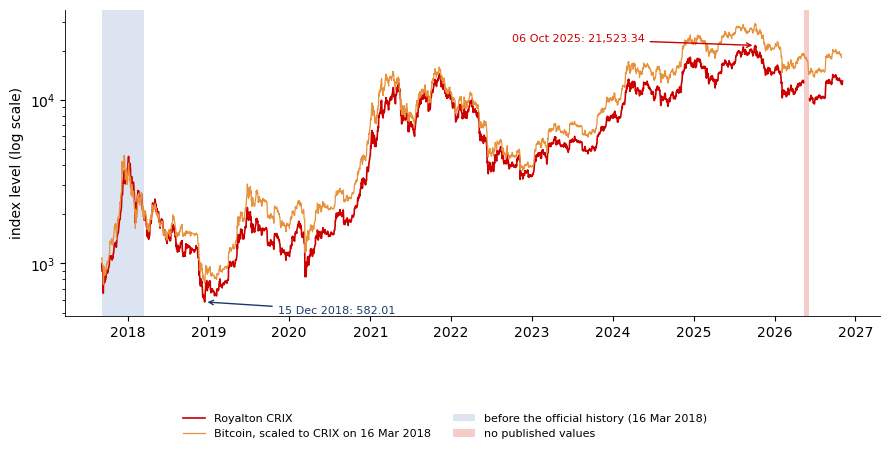

{'full': {'start': '2017-09-06', 'end': '2026-11-06', 'years': 9.166324435318275, 'first': 996.95, 'last': 12250.34, 'cagr': np.float64(31.47895085216703), 'vol': 68.61437999346741, 'n': 3316, 'mdd': -87.09592309124932, 'mdd_peak': '2018-01-05', 'mdd_trough': '2018-12-15'}, 'official': {'start': '2018-03-16', 'end': '2026-11-06', 'years': 8.643394934976044, 'first': 1960.12, 'last': 12250.34, 'cagr': np.float64(23.61690902610345), 'vol': 64.93562476988464, 'n': 3125, 'mdd': -77.43561915453128, 'mdd_peak': '2021-11-08', 'mdd_trough': '2022-11-09'}, 'official_to_oct': {'start': '2018-03-16', 'end': '2026-10-31', 'years': 8.626967830253252, 'first': 1960.12, 'last': 12512.61, 'cagr': np.float64(23.970858042299415), 'vol': 64.95861882524186, 'n': 3121, 'mdd': -77.43561915453128, 'mdd_peak': '2021-11-08', 'mdd_trough': '2022-11-09'}, 'btc_official': {'start': '2018-03-16', 'end': '2026-10-31', 'years': 8.626967830253252, 'first': 8338.349609375, 'last': 77214.2890625, 'cagr': np.float64(29.

In [6]:
# The real CRIX, 6 September 2017 - 6 November 2026, against Bitcoin (EODHD close), and its main episodes
crix = index_series('crix')
btc = daily('BTC-USD.CC').reindex(crix.index)
pk = crix.idxmax()
cs = ann_stats(crix)
cs_off = ann_stats(crix.loc[OFFICIAL:])
bs_off = ann_stats(btc.loc[OFFICIAL:'2026-10-31'])
cs_off_c = ann_stats(crix.loc[OFFICIAL:'2026-10-31'])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(crix.index, crix, color=RED, lw=1.2, label='Royalton CRIX')
ax.plot(btc.index, btc / btc.loc[OFFICIAL] * crix.loc[OFFICIAL], color=BTC, lw=0.9, label=f'Bitcoin, scaled to CRIX on {pd.Timestamp(OFFICIAL):%d %b %Y}')
ax.axvspan(crix.index[0], pd.Timestamp(OFFICIAL), color='#C5D2E8', alpha=0.6, lw=0, label='before the official history (16 Mar 2018)')
ax.axvspan(pd.Timestamp('2026-05-14'), pd.Timestamp('2026-06-07'), color='#F4C7C3', alpha=0.9, lw=0, label='no published values')
ax.annotate(f'{pk:%d %b %Y}: {crix.max():,.2f}', xy=(pk, crix.max()), xytext=(pk - pd.Timedelta(days=1100), crix.max() * 1.05), fontsize=8,
            color=RED, arrowprops=dict(arrowstyle='->', color=RED))
tr = crix.loc[:'2019'].idxmin()
ax.annotate(f'{tr:%d %b %Y}: {crix.loc[tr]:,.2f}', xy=(tr, crix.loc[tr]), xytext=(tr + pd.Timedelta(days=330), crix.loc[tr] * 0.85), fontsize=8,
            color=BLUE, arrowprops=dict(arrowstyle='->', color=BLUE))
ax.set_yscale('log'); ax.set_ylabel('index level (log scale)')
legend_below(fig, ncol=2, bottom=0.2)
fix_years(fig); save_fig(fig, 'ba_l3_crix_path')
r_c = logret(crix).loc[OFFICIAL:'2026-10-31']; r_b = logret(btc).loc[OFFICIAL:'2026-10-31']
j_ = pd.concat([r_c, r_b], axis=1, keys=['c', 'b']).dropna()
ols = sm.OLS(j_['c'], sm.add_constant(j_['b'])).fit()
gaps = crix.isna()
RES['crix'] = dict(full=cs, official=cs_off, official_to_oct=cs_off_c, btc_official=bs_off, peak=float(crix.max()), peak_date=f'{pk:%Y-%m-%d}',
                   n_obs=int(crix.notna().sum()), n_missing=int(gaps.sum()), gap_from='2026-05-14', gap_to='2026-06-07',
                   corr_btc=float(j_['c'].corr(j_['b'])), beta_btc=float(ols.params['b']), beta_se=float(ols.bse['b']), r2_btc=float(ols.rsquared),
                   n_joint=len(j_), vol_c=float(j_['c'].std() * np.sqrt(365)), vol_b=float(j_['b'].std() * np.sqrt(365)),
                   te_btc=float((j_['c'] - j_['b']).std() * np.sqrt(365)),
                   latest=float(crix.dropna().iloc[-1]), latest_date=f'{crix.dropna().index[-1]:%Y-%m-%d}',
                   from_peak=100 * float(crix.dropna().iloc[-1] / crix.max() - 1),
                   worst_day=float(r_c.min()), worst_date=f'{r_c.idxmin():%Y-%m-%d}', best_day=float(r_c.max()), best_date=f'{r_c.idxmax():%Y-%m-%d}',
                   skew=float(stats.skew(r_c.dropna())), exkurt=float(stats.kurtosis(r_c.dropna())))
print(RES['crix'])

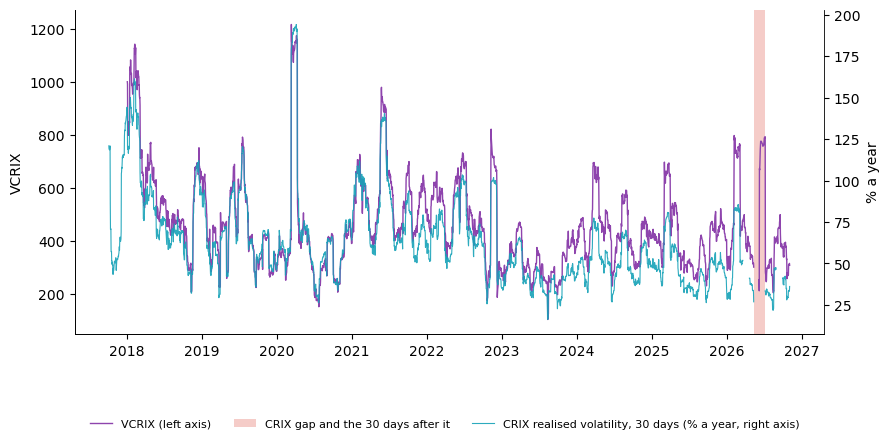

{'first': 1000.0, 'first_date': '2018-01-04', 'mean': 457.70289905362773, 'median': 426.69, 'max': 1215.57, 'max_date': '2020-03-13', 'min': 105.09, 'min_date': '2023-08-14', 'latest': 342.13, 'latest_date': '2026-11-06', 'corr_rv': 0.9302554398040197, 'corr_rv_l1': 0.9432089352098298, 'n': 3020, 'slope_rv': 6.114859570777094, 'const_rv': 74.3775007887071, 'r2_rv': 0.8896430954596599, 'p80': 582.4820000000001, 'p20': 315.31800000000004, 'jump_2020': {'before': 405.66, 'after': 1215.57, 'd30_before': 1159.78, 'd30_after': 542.82}, 'jump_2026': {'before': 213.04, 'after': 673.24, 'out_before': 793.12, 'out_after': 283.93}}


In [7]:
# VCRIX, 4 January 2018 - 6 November 2026, and the realised volatility of CRIX (30 days, annualised)
vcrix = index_series('vcrix')
rc_ = logret(crix)
rv30 = np.sqrt((rc_ ** 2).rolling(30, min_periods=30).mean() * 365)        # % a year, from consecutive-day returns only
art = (vcrix.index >= '2026-05-14') & (vcrix.index <= '2026-07-08')        # data gap and the 30 days after it
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(vcrix.index, vcrix, color=PURPLE, lw=1.0, label='VCRIX (left axis)')
ax.axvspan(pd.Timestamp('2026-05-14'), pd.Timestamp('2026-07-08'), color='#F4C7C3', alpha=0.9, lw=0, label='CRIX gap and the 30 days after it')
ax.set_ylabel('VCRIX')
ax2 = ax.twinx()
ax2.plot(rv30.index, rv30, color=TEAL, lw=0.8, alpha=0.9, label='CRIX realised volatility, 30 days (% a year, right axis)')
ax2.set_ylabel('% a year'); ax2.spines['right'].set_visible(True)
legend_below(fig, ncol=3, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_vcrix_path')
v_ok = vcrix.copy(); v_ok[art] = np.nan
jj = pd.concat([v_ok, rv30, rv30.shift(1)], axis=1, keys=['v', 'rv', 'rv_l1']).loc[:'2026-05-13'].dropna()
fitv = sm.OLS(jj['v'], sm.add_constant(jj['rv_l1'])).fit()
RES['vcrix'] = dict(first=float(vcrix.dropna().iloc[0]), first_date=f'{vcrix.dropna().index[0]:%Y-%m-%d}', mean=float(v_ok.mean()), median=float(v_ok.median()),
                    max=float(v_ok.max()), max_date=f'{v_ok.idxmax():%Y-%m-%d}', min=float(v_ok.min()), min_date=f'{v_ok.idxmin():%Y-%m-%d}',
                    latest=float(vcrix.dropna().iloc[-1]), latest_date=f'{vcrix.dropna().index[-1]:%Y-%m-%d}',
                    corr_rv=float(jj['v'].corr(jj['rv'])), corr_rv_l1=float(jj['v'].corr(jj['rv_l1'])), n=len(jj),
                    slope_rv=float(fitv.params['rv_l1']), const_rv=float(fitv.params['const']), r2_rv=float(fitv.rsquared),
                    p80=float(v_ok.quantile(0.8)), p20=float(v_ok.quantile(0.2)),
                    jump_2020=dict(before=float(vcrix.loc['2020-03-12']), after=float(vcrix.loc['2020-03-13']),
                                   d30_before=float(vcrix.loc['2020-04-11']), d30_after=float(vcrix.loc['2020-04-12'])),
                    jump_2026=dict(before=float(vcrix.loc['2026-06-09']), after=float(vcrix.loc['2026-06-10']),
                                   out_before=float(vcrix.loc['2026-07-08']), out_after=float(vcrix.loc['2026-07-09'])))
print(RES['vcrix'])

## Model

$\mathrm{RV}_{t+1:t+30} = c + \beta_d\mathrm{RV}^{(1)}_t + \beta_w\mathrm{RV}^{(7)}_t + \beta_m\mathrm{RV}^{(30)}_t + u_t$,
OLS with HAC standard errors; chronological train/test split.

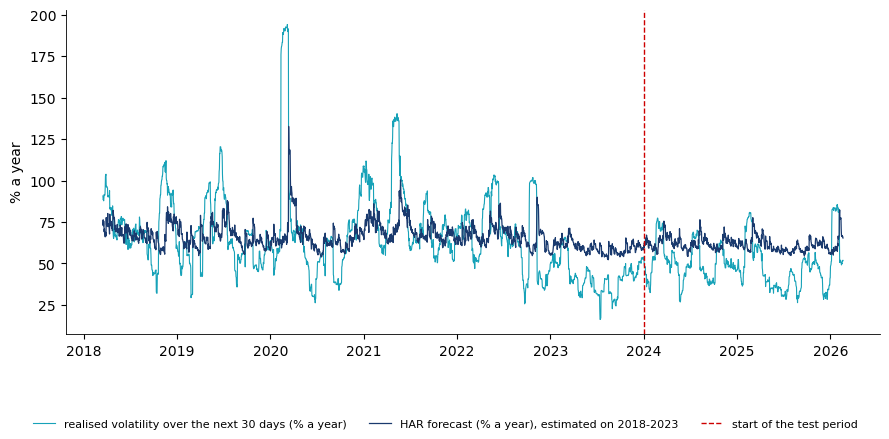

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         48.0241      6.493      7.396      0.000      35.297      60.751
d              0.0212      0.007      2.941      0.003       0.007       0.035
w              0.1121      0.042      2.644      0.008       0.029       0.195
m              0.1526      0.089      1.709      0.087      -0.022       0.328
{'n_train': 2117, 'n_test': 781, 'params': {'const': 48.02413443980273, 'd': 0.021204987771311856, 'w': 0.11209367274538638, 'm': 0.152592574491371}, 'se': {'const': 6.493331764808969, 'd': 0.007209635253063457, 'w': 0.04239363164263818, 'm': 0.08927126985327458}, 'r2_train': 0.08847139150425387, 'r2_oos': 0.26837182656570824, 'r2_oos_naive': 0.24614833947666004, 'corr_har_vcrix': 0.7938355087156749, 'corr_har_vcrix_test': 0.7263815128667661, 'rmse_test': 18.36929856780346, 'rmse_naive': 18.646198813427358}


In [8]:
# Own HAR model (Corsi, 2009) for the next 30 days' realised volatility of CRIX; train to end-2023, test from 2024
a_ = np.abs(rc_) * np.sqrt(365)                                           # daily component, % a year
rv7 = np.sqrt((rc_ ** 2).rolling(7, min_periods=7).mean() * 365)        # weekly component
fut = np.sqrt((rc_ ** 2).rolling(30, min_periods=30).mean().shift(-30) * 365)   # target: realised vol over t+1..t+30
H = pd.concat([fut, a_, rv7, rv30, v_ok], axis=1, keys=['y', 'd', 'w', 'm', 'v']).loc[OFFICIAL:'2026-05-13']
H = H.dropna(subset=['y', 'd', 'w', 'm'])
tr_, te_ = H.loc[:'2023-12-31'], H.loc['2024-01-01':]
har = sm.OLS(tr_['y'], sm.add_constant(tr_[['d', 'w', 'm']])).fit(cov_type='HAC', cov_kwds={'maxlags': 30})
pred = har.predict(sm.add_constant(H[['d', 'w', 'm']]))
oos_r2 = 1 - ((te_['y'] - pred.loc[te_.index]) ** 2).sum() / ((te_['y'] - tr_['y'].mean()) ** 2).sum()
naive_r2 = 1 - ((te_['y'] - te_['m']) ** 2).sum() / ((te_['y'] - tr_['y'].mean()) ** 2).sum()
vv = pd.concat([pred, H['v']], axis=1, keys=['p', 'v']).dropna()
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(H.index, H['y'], color=TEAL, lw=0.8, label='realised volatility over the next 30 days (% a year)')
ax.plot(pred.index, pred, color=BLUE, lw=0.9, label='HAR forecast (% a year), estimated on 2018-2023')
ax.axvline(pd.Timestamp('2024-01-01'), color=RED, ls='--', lw=1, label='start of the test period')
ax.set_ylabel('% a year')
legend_below(fig, ncol=3, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_vcrix_har')
RES['har'] = dict(n_train=len(tr_), n_test=len(te_), params={k: float(v) for k, v in har.params.items()},
                  se={k: float(v) for k, v in har.bse.items()}, r2_train=float(har.rsquared), r2_oos=float(oos_r2), r2_oos_naive=float(naive_r2),
                  corr_har_vcrix=float(vv['p'].corr(vv['v'])), corr_har_vcrix_test=float(vv.loc['2024':, 'p'].corr(vv.loc['2024':, 'v'])),
                  rmse_test=float(np.sqrt(((te_['y'] - pred.loc[te_.index]) ** 2).mean())),
                  rmse_naive=float(np.sqrt(((te_['y'] - te_['m']) ** 2).mean())))
print(har.summary().tables[1]); print(RES['har'])